In [12]:
#1.1
import pandas as pd

#读取文件数据并将其命名为 Sig_Eqs 
Sig_Eqs = pd.read_csv("earthquakes-2026-10-14_21-39-07_+0800.tsv",sep="\t")

# 取出需要的国家和死亡人数两列
country_deaths_data = Sig_Eqs[["Country", "Deaths"]]

# 按国家分组
country_groups = country_deaths_data.groupby(['Country'])
# 计算每个国家的死亡总人数
total_deaths_series = country_groups["Deaths"].sum()
#把结果从 Series 转成表格
total_deaths_table = total_deaths_series.reset_index()
# 给总死亡人数列改一个清晰的列名
total_deaths_table = total_deaths_table.rename(columns={"Deaths": "TotalDeaths"})

# 按总死亡人数从高到低排序
total_deaths_table = total_deaths_table.sort_values(["TotalDeaths"],ascending=False)
# 取总死亡人数前 20 个国家
top20_countries = total_deaths_table.head(20)
# 输出排名前 20 个国家的列表以及它们的死亡人数
print(top20_countries.to_string(index=False))

     Country  TotalDeaths
       CHINA    2139209.0
      TURKEY    1199720.0
        IRAN    1014453.0
       ITALY     492236.0
       SYRIA     419826.0
       HAITI     323484.0
  AZERBAIJAN     319251.0
       JAPAN     242516.0
     ARMENIA     177890.0
    PAKISTAN     145085.0
        IRAQ     136200.0
     ECUADOR     135496.0
TURKMENISTAN     117412.0
        PERU     102309.0
      ISRAEL      93388.0
    PORTUGAL      83572.0
      GREECE      81162.0
       CHILE      64277.0
       INDIA      63507.0
      TAIWAN      57154.0


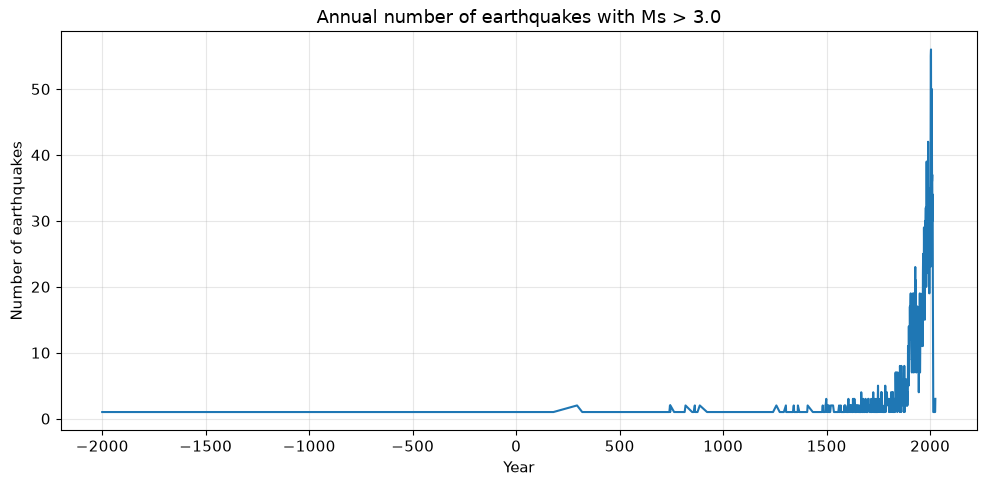

In [13]:
#1.2
import pandas as pd
import matplotlib.pyplot as plt

#读取文件数据并将其命名为 Sig_Eqs 
Sig_Eqs = pd.read_csv("earthquakes-2026-10-14_21-39-07_+0800.tsv",sep="\t")

#筛选 Ms > 3.0 的地震记录存为新变量 eq_m3
eq_m3 = Sig_Eqs[Sig_Eqs["Ms"] > 3.0]
# 按年份分组计算每年地震数量
year_counts = eq_m3.groupby("Year").size()

#新建一张图画布，画布宽 10 英寸、高 5 英寸
plt.figure(figsize=(10, 5))
#画折线，X轴为年份，Y轴为每年地震数量，线宽 1.5
plt.plot(year_counts.index, year_counts.values, linewidth=1.5)
#X轴标签为 Year
plt.xlabel("Year")
#Y轴标签为 Number of earthquakes
plt.ylabel("Number of earthquakes")
#图表标题为 Annual number of earthquakes with Ms > 3.0
plt.title("Annual number of earthquakes with Ms > 3.0")
#在图上画横竖网格线，透明度为 30%
plt.grid(alpha=0.3)
#自动调整间距
plt.tight_layout()
#绘制图表
plt.show()

In [14]:
#1.3
import pandas as pd


#读取文件数据并将其命名为 Sig_Eqs 
Sig_Eqs = pd.read_csv("earthquakes-2026-10-14_21-39-07_+0800.tsv",sep="\t")


# 自定义一个函数 CountEq_LargestEq，country_name 是要查询的国家，df = Sig_Eqs 是可选参数来自地震数据表
def CountEq_LargestEq(country_name, df=Sig_Eqs): 
    #在数据表里面，取出这个国家全部地震记录，存入 country_data
    country_data = df[df["Country"] == country_name]
    #用 len() 统计行数，得到该国家地震总数
    total_eq_num = len(country_data)
    #如果这个国家一条地震记录都没有，直接返回总数 0，日期、地点都是空值
    if total_eq_num == 0:
        return 0, (None, None)

    
    # 使用 Ms 作为震级指标找出最大地震
    #首先 if 判断 Ms 这一列数据不是空值的情况下，用 .idxmax() 找出 Ms 数值最大那一行的行标签
    if country_data["Ms"].notna().any():
        max_mag_row = country_data.loc[   #用 .loc[...] 根据行标签取出完整那一行的数据，赋值给 max_mag_row
            country_data["Ms"].idxmax()
        ]
    #Ms缺失，但该国只有一次地震，即取这次地震为该国最大地震，.iloc[0] 按位置取第 0 行（第一行）
    elif total_eq_num == 1:
        max_mag_row = country_data.iloc[0]
    #Ms缺失，并且该国有多次地震，无法判断哪次地震最大：返回地震总数，日期地点为空
    else:
        return total_eq_num, (None, None)

    
    #从最强地震那一行，取出年份、月份、日期三列的值
    year = max_mag_row["Year"]
    month = max_mag_row["Mo"]
    day = max_mag_row["Dy"]

    
    #如果年份本身是空值，最终日期直接记为 None
    if pd.isna(year):
        eq_date = None
    #年份非空情况下再判断，如果年份小于 0，转换成年份的相反数加上 BC 表示公元前；如果大于 0，转为字符串
    else:
        if year < 0:
            year_text = f"{abs(int(year))} BC"
        else:
            year_text = str(int(year))
        #假如月份是空值，只保留年份
        if pd.isna(month):
            eq_date = year_text
        #假如有月份，日期是空值，只输出年份和月份，月份是两位数，年月用 - 连接
        elif pd.isna(day):
            eq_date = f"{year_text}-{int(month):02d}"
        #假如有年份，月份和日期，输出年月日，用 - 连接，月份和日期是两位数
        else:
            eq_date = (
                f"{year_text}-"
                f"{int(month):02d}-"
                f"{int(day):02d}"
            )

    
    #从最强地震行，取出地点名称
    eq_location = max_mag_row["Location Name"]

    #函数返回两个内容：地震总数，以及（日期，地点）这个元组
    return total_eq_num, (eq_date, eq_location)


#取出所有非空国家名并去重，排除国家名为空的那一行
all_countries = Sig_Eqs["Country"].dropna().unique()

#创建空列表，用来保存每个国家的结果
result_list = []

#采用 for 循环逐个遍历每一个国家
for country in all_countries:
    #CountEq_LargestEq(country, Sig_Eqs)调用函数，明确传入当前国家和数据表
    #total_eq_num, (eq_date, eq_location)把函数返回的总数、日期和地点分别赋给变量
    total_eq_num, (eq_date, eq_location) = CountEq_LargestEq(country, Sig_Eqs)

    #把当前国家的结果（国家，地震总数，该国家有史以来发生的最大规模地震的日期和地点）保存为字典，加入列表
    result_list.append({
        "Country": country,
        "Total_Earthquake_Count": total_eq_num,
        "Largest_EQ_Date": eq_date,
        "Largest_EQ_Location": eq_location
    })

#把装满字典的列表，转换成 DataFrame 表格
result_df = pd.DataFrame(result_list)


# 定义一个函数 chronological_key，把我们拼接好的文本日期转成数字，方便从小到大排序
def chronological_key(date_text):
    #如果日期是空，返回无穷大 inf，排序时自动排到表格最后面
    if date_text is None or pd.isna(date_text):
        return float("inf")

    #按-分割日期字符串
    parts = str(date_text).split("-")
    #取出第一部分年份文本
    year_text = parts[0]
    #如果结尾是 BC 公元前，采用切片去掉末尾 3 个数即去掉 BC，并转成负数；公元后直接转正数。
    if year_text.endswith(" BC"):
        year = -int(year_text[:-3])
    else:
        year = int(year_text)

    #有月份就取月份，没有月份填 0；有日期就取日期，没有填 0。
    month = int(parts[1]) if len(parts) > 1 else 0
    day = int(parts[2]) if len(parts) > 2 else 0

    #生成类似 20260524 的排序值，年份优先，其次月份，最后日期
    return year * 10000 + month * 100 + day

#.apply() 表示对 Largest_EQ_Date 这一列的每一条日期，都跑一遍 chronological_key，生成数字排序键，存到新增临时列 _SortKey
result_df["_SortKey"] = result_df["Largest_EQ_Date"].apply(chronological_key)


result_df = (
    result_df
    .sort_values("_SortKey", ascending=True)    #根据排序升序排列,从公元前到近代
    .drop(columns="_SortKey")                   #删掉刚才用来排序的临时列
    .reset_index(drop=True)                     #重新生成新的序号，不保留旧索引
)


#固定最终结果的输出形式，按照按国家，地震总数，该国家有史以来发生的最大规模地震的日期和地点输出，以日期作为排序标准
result_df = result_df[[ "Country", "Total_Earthquake_Count", "Largest_EQ_Date", "Largest_EQ_Location"]]
#max_colwidth=25防止输出换行错位
print(result_df.to_string(index=False, max_colwidth=25))

                  Country  Total_Earthquake_Count Largest_EQ_Date       Largest_EQ_Location
                   JORDAN                       5       362-05-24         JORDAN:  AL-KARAK
                   GREECE                     296       365-07-21  GREECE:  CRETE:  KNOSSOS
                     IRAN                     385       856-12-22     IRAN:  DAMGHAN, QUMIS
                    JAPAN                     429       869-07-13           JAPAN:  SANRIKU
                    SYRIA                      34      1202-05-20      SYRIA:  SOUTHWESTERN
                  IRELAND                       1            1490     IRELAND:  SLIGO, MAYO
                    NEPAL                      21      1505-06-06               NEPAL-INDIA
                 SLOVENIA                      22      1511-03-26 BALKANS NW:  SLOVENIA:...
                     PERU                     195      1619-02-14 PERU:  TRUJILLO, PIURA...
              SOUTH KOREA                      22      1643-07-25              S

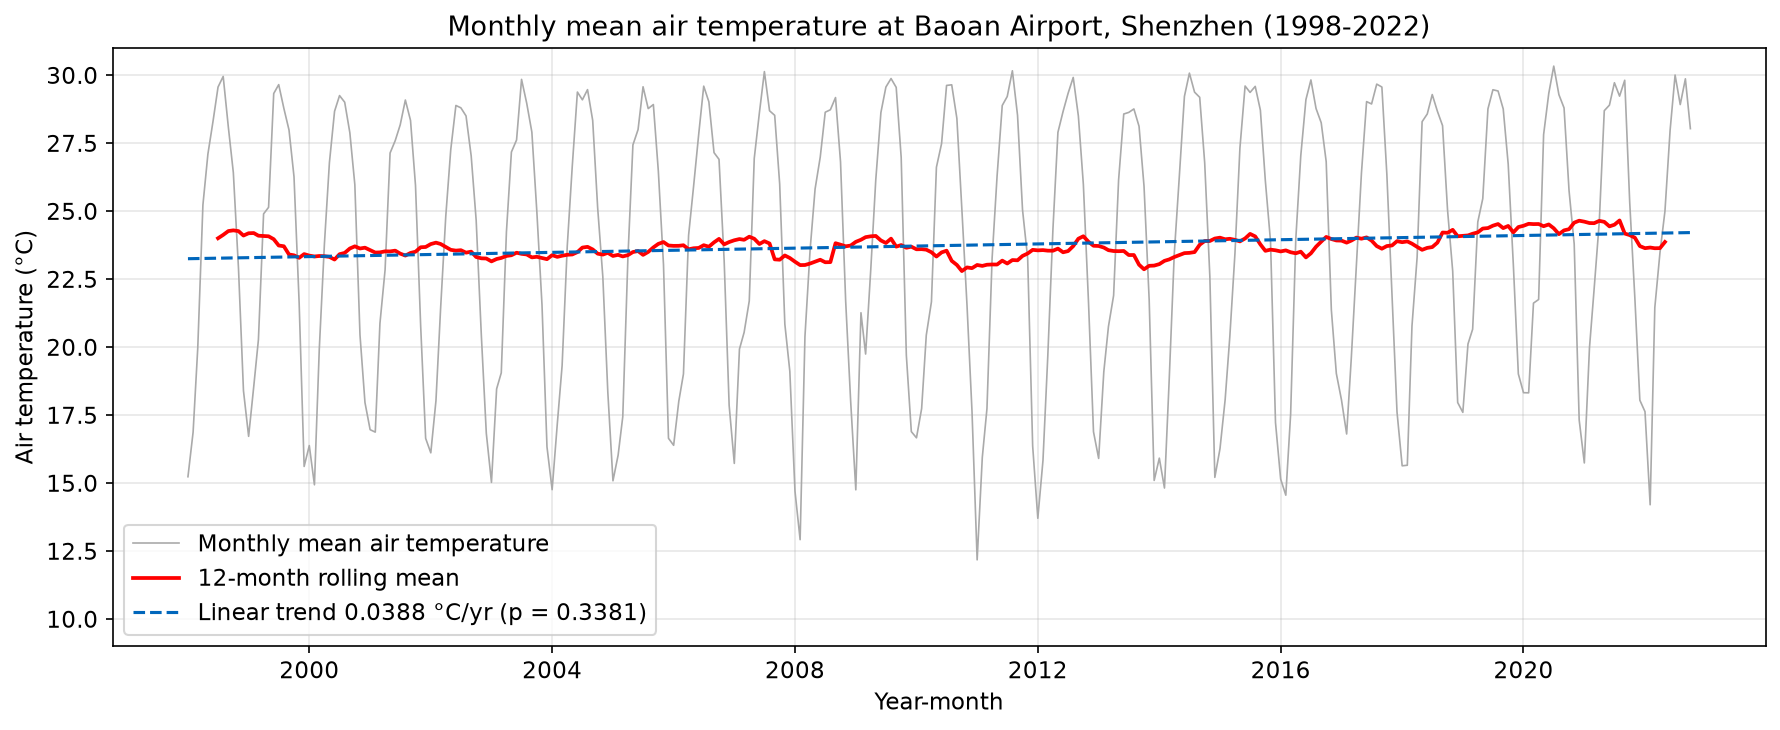

In [4]:
#2
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
#从 scipy 科学计算库里面导入统计模块 stats，用来做线性回归
from scipy import stats


#读取 csv 气象文件，存入表格变量 df，low_memory=False 避免读文件时类型报警
df = pd.read_csv("Baoan_Weather_1998_2022.csv", low_memory=False)


#TMP 这一列是类似 186,1 这种用逗号隔开的字符串，按逗号切开，变成两列表格
tmp_split = df["TMP"].str.split(",", expand=True)
#切开后第 0 列，是气温原始数字字符串，存到新列 tmp_val 
df["tmp_val"] = tmp_split[0]
#切开后第 1 列是质控码，转成整数类型，存到 tmp_qc 
df["tmp_qc"] = tmp_split[1].astype(int)

#把 tmp_val 气温字符串转数字，转不了的数据直接变成缺失值 NaN
df["tmp_val"] = pd.to_numeric(df["tmp_val"], errors="coerce")
#ISD规范里 9999 代表气温缺测，把 tmp_val 里的 9999 替换成缺失值 NaN
df.loc[df["tmp_val"] == 9999, "tmp_val"] = np.nan
#原始数据单位是 0.1℃，除以 10 换算成摄氏度，结果存入 temp_c
df["temp_c"] = df["tmp_val"] / 10


#定义坏质控码列表，ISD 规范里 2、3、6、7 代表数据有明确问题，需要剔除
bad_qc = [2, 3, 6, 7]
#判断 tmp_qc 这一列每行的质控码是不是在坏码清单里，不是的存入 good_mask 
good_mask = df["tmp_qc"].isin(bad_qc) == False
#复制 good_mask 的数据存为 df_filtered 
df_filtered = df[good_mask].copy()
#删掉气温 temp_c 是缺失值 NaN 的行
df_filtered = df_filtered.dropna(subset=["temp_c"])


#把 DATE 文本列，转换成 pandas 的日期时间类型，以便提取年月和绘图
df_filtered["DATE"] = pd.to_datetime(df_filtered["DATE"])
#将每条观测记录对应到具体月份
df_filtered["year_month"] = df_filtered["DATE"].dt.to_period("M")
#按年月分组，计算每个月气温平均值， reset_index() 把分组结果变回普通表格
monthly_temp = df_filtered.groupby("year_month")["temp_c"].mean().reset_index()
#将月份转换为日期时间，便于用日期坐标绘图
monthly_temp["time_dt"] = monthly_temp["year_month"].dt.to_timestamp()
#生成小数年份，用来做回归计算趋势
monthly_temp["decimal_year"] = monthly_temp["time_dt"].dt.year + monthly_temp["time_dt"].dt.month / 12

#计算 12 个月中心滚动平均，每个点使用前后共 12 个月的数据，可以平滑季节波动。序列首尾不足 12 个月的位置会是 NaN
monthly_temp["roll12"] = monthly_temp["temp_c"].rolling(window=12, center=True).mean()

#提取时间变量，并将其转换为 NumPy 数组
x = monthly_temp["decimal_year"].values
#提取月平均气温，并将其转换为 NumPy 数组
y = monthly_temp["temp_c"].values
#一元线性回归，输出 5 个结果：斜率 slope、截距 intercept、相关系数 r、p 值 p、标准误 se
slope, intercept, r, p, se = stats.linregress(x, y)
#用回归公式，算出趋势线上每个点的 y 值（拟合线）
y_fit = slope * x + intercept


# 绘图，全局设置图上文字字号为 11，新建画布，宽 12、高 5 英寸，分辨率 150
plt.rcParams['font.size'] = 11
plt.figure(figsize=(12,5), dpi=150)
# 浅灰色是原始按月平均气温，线宽为 0.8
plt.plot(monthly_temp["time_dt"], monthly_temp["temp_c"], color="#aaaaaa", lw=0.8, label="Monthly mean air temperature")
# 红色实线是12个月滚动平均，线宽为1.8，用来观察长期变化
plt.plot(monthly_temp["time_dt"], monthly_temp["roll12"], color="red", lw=1.8, label="12-month rolling mean")
# 蓝色虚线是线性趋势线，线宽为1.5，并在图例中显示斜率和 p 值
plt.plot(monthly_temp["time_dt"], y_fit, color="#0066bb", ls="--", lw=1.5, label=f"Linear trend {slope:.4f} °C/yr (p = {p:.4f})")

#X轴标签为 Year-month
plt.xlabel("Year-month")
#Y轴标签为 Air temperature (°C)
plt.ylabel("Air temperature (°C)")
#图表标签为 Monthly mean air temperature at Baoan Airport, Shenzhen (1998-2022)
plt.title("Monthly mean air temperature at Baoan Airport, Shenzhen (1998-2022)")
#为了防止图标影响折线，设置Y轴范围为10到31
plt.ylim(9, 31)   
#自动显示图例
plt.legend()
#在图上画横竖网格线，透明度为 30%
plt.grid(alpha=0.3)
#自动调整间距
plt.tight_layout()
#绘制图表
plt.show()


==== 3.1 ====
             SID storm_name  max_wmo_wind
0  2015293N13266   PATRICIA         185.0
1  1980214N11330      ALLEN         165.0
2  1988253N12306    GILBERT         160.0
3  1997253N12255      LINDA         160.0
4  2005289N18282      WILMA         160.0
5  2019236N10314     DORIAN         160.0
6  1998295N12284      MITCH         155.0
7  2005261N21290       RITA         155.0
8  2009288N07267       RICK         155.0
9  2017242N16333       IRMA         155.0

==== 3.2 ====
[185.0, 165.0, 160.0, 160.0, 160.0, 160.0, 155.0, 155.0, 155.0, 155.0, 150.0, 150.0, 150.0, 150.0, 150.0, 150.0, 150.0, 150.0, 150.0, 150.0]

==== 3.3 ====
BASIN
WP    236576
SI    160668
NA    124881
SP     67119
EP     62412
NI     55402
SA       119
Name: count, dtype: int64

==== 3.4 ====


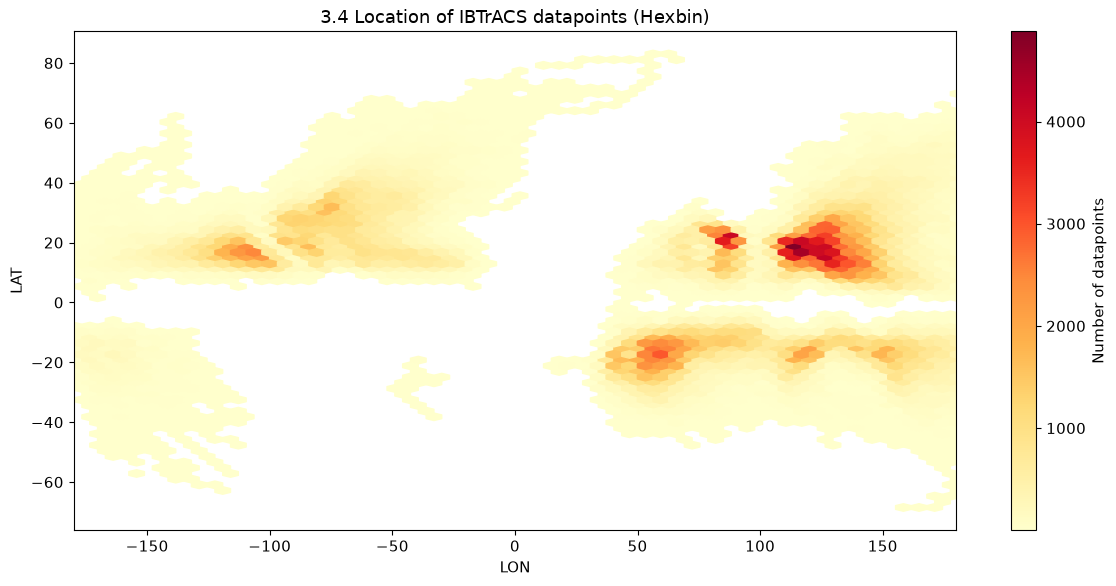


==== 3.5: Mangkhut 2018 record count: 99


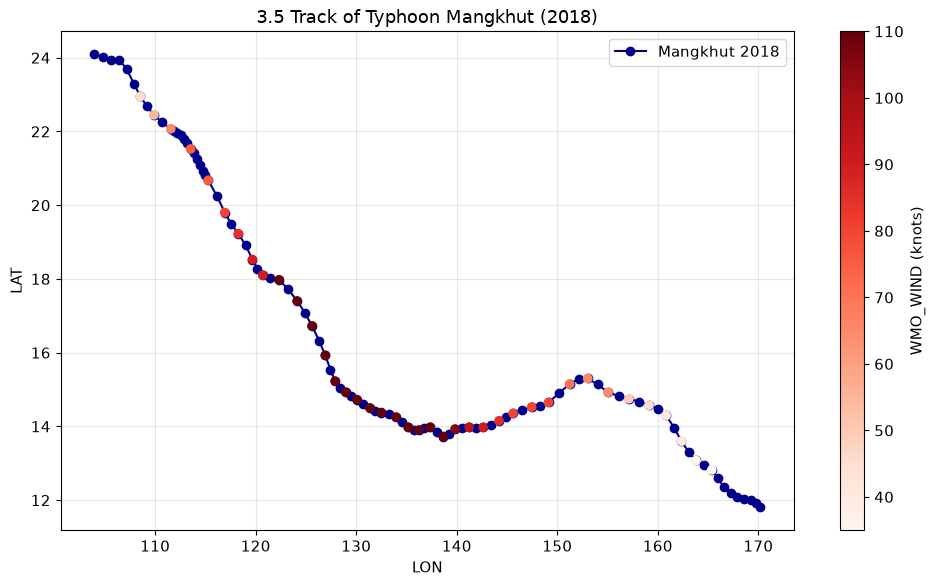


==== 3.6 ====
BASIN
WP    122301
EP     54051
Name: count, dtype: int64
WP + EP total datapoints: 176352

==== 3.7 ====


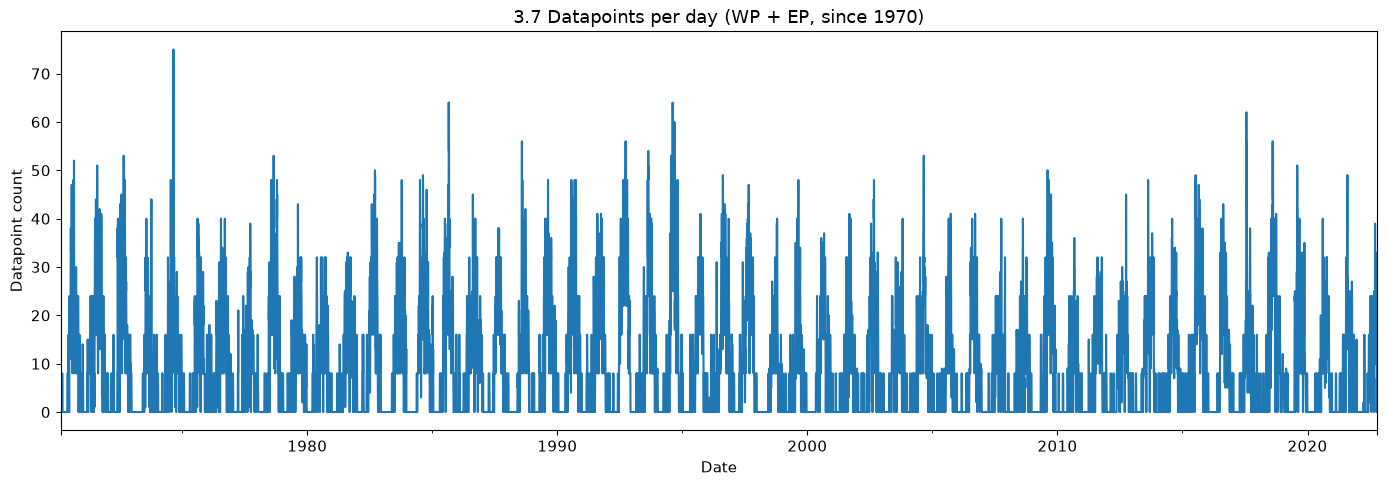


==== 3.8 ====


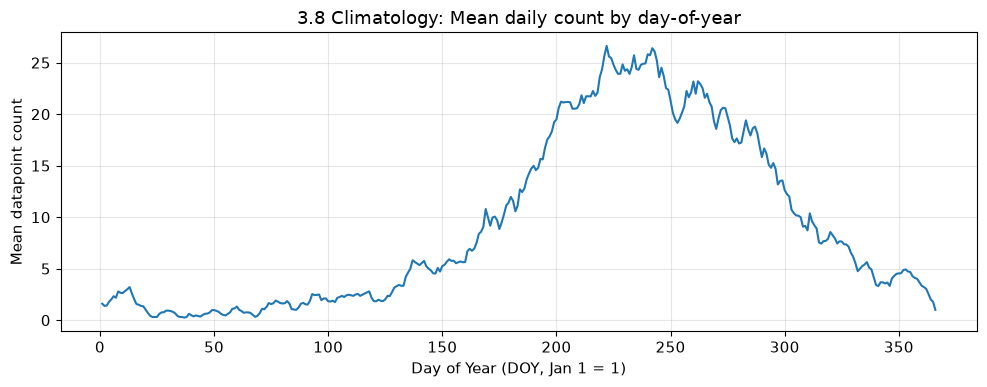


==== 3.9 ====
count    19229.000000
mean         0.000000
std          7.389795
min        -26.094340
25%         -3.584906
50%         -1.019231
75%          3.500000
max         50.113208
Name: anomaly, dtype: float64

==== 3.10 ====


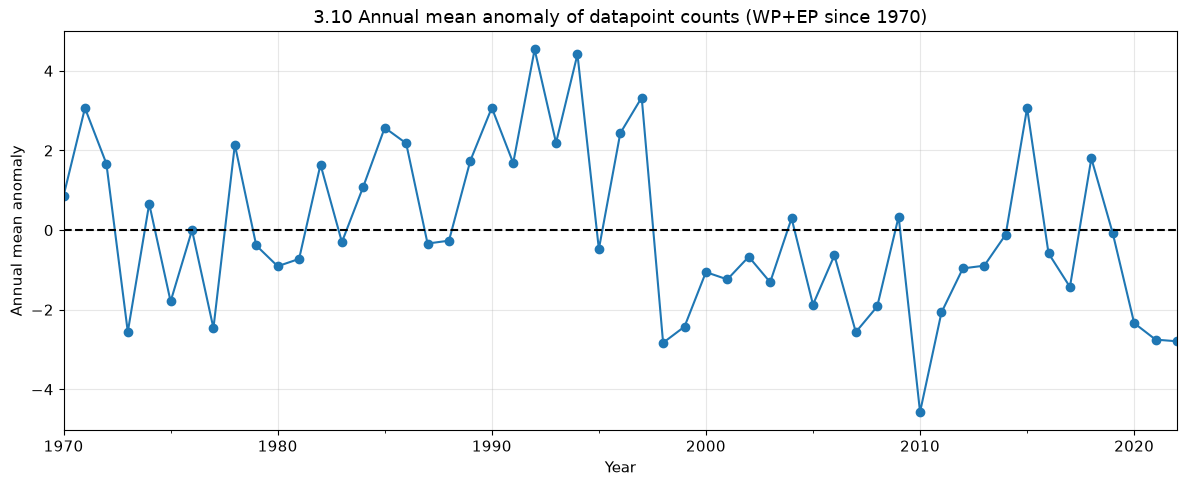

| ISO_TIME            |   annual_anomaly |
|:--------------------|-----------------:|
| 1970-12-31 00:00:00 |         0.860986 |
| 1971-12-31 00:00:00 |         3.065001 |
| 1972-12-31 00:00:00 |         1.668648 |
| 1973-12-31 00:00:00 |        -2.556917 |
| 1974-12-31 00:00:00 |         0.659521 |
| 1975-12-31 00:00:00 |        -1.792533 |
| 1976-12-31 00:00:00 |        -0.000750 |
| 1977-12-31 00:00:00 |        -2.463766 |
| 1978-12-31 00:00:00 |         2.144453 |
| 1979-12-31 00:00:00 |        -0.387054 |
| 1980-12-31 00:00:00 |        -0.907854 |
| 1981-12-31 00:00:00 |        -0.724040 |
| 1982-12-31 00:00:00 |         1.645823 |
| 1983-12-31 00:00:00 |        -0.302122 |
| 1984-12-31 00:00:00 |         1.094878 |
| 1985-12-31 00:00:00 |         2.571850 |
| 1986-12-31 00:00:00 |         2.180069 |
| 1987-12-31 00:00:00 |        -0.337739 |
| 1988-12-31 00:00:00 |        -0.265778 |
| 1989-12-31 00:00:00 |         1.747193 |
| 1990-12-31 00:00:00 |         3.073220 |
| 1991-12-3

In [21]:
#3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# 读取文件
df = pd.read_csv(
    "ibtracs.ALL.list.v04r00.csv",
    skiprows=[1],                           #跳过不包含数据的第2行
    parse_dates=["ISO_TIME"],               #ISO_TIME 这一列自动解析为 pandas datetime 时间格式，而不是普通字符串
    keep_default_na=False,                  #关闭 pandas 默认的缺失值词表。因为 BASIN="NA" 表示 North Atlantic，不能把它当作缺失值
    na_values=["", "NOT_NAMED", "NAME"],    #把单元格内容等于 NOT_NAMED、NAME 的值识别为缺失值 NaN       
    low_memory=False,                       #让 pandas 一次读取完整数据后再判断类型，减少分块推断造成的类型警告
)

#把这三列强制转为数字；如果里面有文字、乱码无法转数字，就变成 NaN；防止按字符串出现大小对比时出错
df["LAT"] = pd.to_numeric(df["LAT"], errors="coerce")    
df["LON"] = pd.to_numeric(df["LON"], errors="coerce")
df["WMO_WIND"] = pd.to_numeric(df["WMO_WIND"], errors="coerce")



# 3.1
storm_max_wind = (
    df.groupby("SID", as_index=False)        #SID 是每个风暴唯一编号，按风暴编号分组，同一风暴所有观测点归为一组；as_index=False：分组之后 SID 仍然作为普通列，而不是变成索引
      .agg(                                  #.agg() 聚合函数：一组内计算多个统计量
          max_wmo_wind=("WMO_WIND", "max"),  #每组风暴，取这个风暴一生中最强风速，新列名叫 max_wmo_wind
          storm_name=("NAME", "first"),      #每组风暴，取第一个出现的名字作为风暴名称
      )
      .dropna(subset=["max_wmo_wind", "storm_name"])        #删除没有风速或没有名称的风暴
)

# 将排序结果保存为storm_ranked
storm_ranked = (
    storm_max_wind                                                    
    .sort_values("max_wmo_wind", ascending=False, kind="stable")      #按最大风速从大到小降序排序，强风暴排在前面；kind="stable"稳定排序
    .reset_index(drop=True)                                           #重新生成行号，删掉原来旧的索引编号
)


#取排序后前 10 条即为全球最强 10 个风暴
top10_storms = storm_ranked.head(10)
#输出3.1结果，只输出 SID、名字、最大风速三列
print("\n==== 3.1 ====")
print(top10_storms[["SID", "storm_name", "max_wmo_wind"]])



# 3.2
#从同一个 storm_ranked 取前 20 行
top20_storms = storm_ranked.head(20)
#to_list() 把 pandas Series 转成普通 Python 列表，输出只有风速值
top20_winds = top20_storms["max_wmo_wind"].to_list()

#输出3.2的结果
print("\n==== 3.2 ====")
print(top20_winds)



#3.3
#BASIN 是海盆流域代码；.value_counts()：统计 BASIN 里每个类别出现多少次，也就是每个海盆一共有多少条观测记录
basin_counts = df["BASIN"].value_counts()

#输出3.3的结果
print("\n==== 3.3 ====")
print(basin_counts)


#3.4
print("\n==== 3.4 ====")

#新建画布，宽 12 高 6 英寸
plt.figure(figsize=(12, 6))
#横坐标 LON，纵坐标 LAT；gridsize=70 是把画布分成 70×70 个六边形格子；cmap="YlOrRd"是配色，黄→橙→红，红色代表点位很多；mincnt=1：至少有 1 个点才会画这个格子
plt.hexbin(df["LON"], df["LAT"], gridsize=70, cmap="YlOrRd", mincnt=1)
#显示颜色与数据点数量的对应关系
cbar = plt.colorbar()
#生成右侧色条，标注含义 Number of datapoints（每个格子里面观测点数量）
cbar.set_label("Number of datapoints")
#X轴标签为 LON
plt.xlabel("LON")
#Y轴标签为 LAT
plt.ylabel("LAT")
#图表标签为3.4 Location of IBTrACS datapoints (Hexbin)
plt.title("3.4 Location of IBTrACS datapoints (Hexbin)")
#限制X轴范围为-180到180
plt.xlim([-180, 180])
#自动调整间距
plt.tight_layout()
#绘制图表
plt.show()



#3.5
#筛选名字等于 MANGKHUT，年份 SEASON=2018的数据单独复制一份进 mangkhut
mangkhut = df[(df["NAME"] == "MANGKHUT") & (df["SEASON"] == 2018)].copy()
#输出3.5并输出2018 年山竹整个生命周期，一共有多少条观测点位数据
print(f"\n==== 3.5: Mangkhut 2018 record count: {len(mangkhut)}")

#新建画布，宽 10 高 6 英寸
plt.figure(figsize=(10,6))
#用蓝色实线和圆圈，画出台风移动轨迹连线
plt.plot(mangkhut["LON"], mangkhut["LAT"], "-o", color="darkblue", label="Mangkhut 2018")
#散点图，每个观测点颜色由 WMO_WIND 风速决定，红色系；zorder=6让散点画在线条上层，不会被盖住
sc = plt.scatter(mangkhut["LON"], mangkhut["LAT"], c=mangkhut["WMO_WIND"], cmap="Reds", zorder=6)
#生成右侧色条，标注含义 WMO_WIND (knots)
plt.colorbar(sc, label="WMO_WIND (knots)")
#X轴标签为 LON
plt.xlabel("LON")
#Y轴标签为 LAT
plt.ylabel("LAT")
#图表标签为3.5 Track of Typhoon Mangkhut (2018)
plt.title("3.5 Track of Typhoon Mangkhut (2018)")
#自动显示图例
plt.legend()
#在图上画横竖网格线，透明度为 30%
plt.grid(alpha=0.3)
#自动调整间距
plt.tight_layout()
#绘制图表
plt.show()



#3.6
#筛选时间大于等于 1970-01-01，海盆只能是 WP 和 EP的数据单独复制一份进 df_filtered
df_filtered = df[  (df["ISO_TIME"] >= pd.Timestamp("1970-01-01")) & (df["BASIN"].isin(["WP", "EP"]))].copy()

# 统计并输出WP、EP各自数据条数
basin_sub_count = df_filtered["BASIN"].value_counts()
# 计算WP+EP总的数据条数
total_count = len(df_filtered)

#输出3.6的结果
print("\n==== 3.6 ====")
print(basin_sub_count)
print(f"WP + EP total datapoints: {total_count}")



#3.7 
print("\n==== 3.7 ====")

#把时间列设为索引，这是 resample 需要的格式
df_filt_indexed = df_filtered.set_index("ISO_TIME")
#按天 D=day分组；.size() 返回每一天的记录行数；中间没有记录的日子会自动变成 0
daily_count = df_filt_indexed.resample("D").size()


#新建画布，宽 14 高 5 英寸
plt.figure(figsize=(14, 5))
#用前面得到的 daily_count绘图
daily_count.plot()
#X轴标签为 Date
plt.xlabel("Date")
#Y轴标签为 Datapoint count
plt.ylabel("Datapoint count")
#图表标签为3.7 Datapoints per day (WP + EP, since 1970)
plt.title("3.7 Datapoints per day (WP + EP, since 1970)")
#自动调整间距
plt.tight_layout()
#绘制图表
plt.show()



#3.8
print("\n==== 3.8 ====")

#把刚才 daily_count 变回普通表格，计数列命名为 count
daily_df = daily_count.reset_index(name="count")
#提取时间的积日 DOY
daily_df["doy"] = daily_df["ISO_TIME"].dt.dayofyear
#把所有年份里，同一个积日放在一起求平均值，得到气候态，一年中每一天长期平均观测数量
clim_doy = daily_df.groupby("doy")["count"].mean()

#新建画布，宽 14 高 5 英寸
plt.figure(figsize=(10,4))
#用前面得到的 clim_doy 绘图
clim_doy.plot()

#X轴标签为 Day of Year (DOY, Jan 1 = 1)
plt.xlabel("Day of Year (DOY, Jan 1 = 1)")
#Y轴标签为 Mean datapoint count
plt.ylabel("Mean datapoint count")
#图表标签为3.8 Climatology: Mean daily count by day-of-year
plt.title("3.8 Climatology: Mean daily count by day-of-year")
#在图上画横竖网格线，透明度为 30%
plt.grid(alpha=0.3)
#自动调整间距
plt.tight_layout()
#绘制图表
plt.show()



#3.9
#根据这一行的 doy 积日，去匹配刚才算好的气候平均值 clim_doy，填入新列 clim
daily_df["clim"] = daily_df["doy"].map(clim_doy)
# 计算异常anomaly=当日计数 − 该积日的气候态均值
daily_df["anomaly"] = daily_df["count"] - daily_df["clim"]

# 对全部异常序列做统计分析，只输出汇总指标
print("\n==== 3.9 ====")
print(daily_df["anomaly"].describe())



#3.10
print("\n==== 3.10 ====")

#用异常值构造新的 Series，并把日期设为索引
anom_series = pd.Series(daily_df["anomaly"].values, index=daily_df["ISO_TIME"])
#按自然年分组，一年里面所有逐日异常取平均
annual_anomaly = anom_series.resample("YE").mean()

#新建画布，宽 12 高 5 英寸
plt.figure(figsize=(12,5))
#绘制 annual_anomaly 的折线图，并用圆圈进行标记
annual_anomaly.plot(marker="o")
#画一条 y=0 黑色虚线，作为异常零线，线上 = 偏多，线下 = 偏少
plt.axhline(y=0, color="black", linestyle="--")

#X轴标签为 Year
plt.xlabel("Year")
#Y轴标签为 Annual mean anomaly
plt.ylabel("Annual mean anomaly")
#图表标签为3.10 Annual mean anomaly of datapoint counts (WP+EP since 1970)
plt.title("3.10 Annual mean anomaly of datapoint counts (WP+EP since 1970)")
#在图上画横竖网格线，透明度为 30%
plt.grid(alpha=0.3)
#自动调整间距
plt.tight_layout()
#绘制图表
plt.show()

#输出3.10的结果
df_table = annual_anomaly.reset_index()
df_table.columns = ["ISO_TIME", "annual_anomaly"]
print(df_table.to_markdown(index=False, floatfmt=".6f"))

==== 4.1 ====
原始数据行数： 58662
清洗后行数： 58572
                   time_utc        time         mf  mf_repeatability  \
0 2003-12-09 01:15:00+00:00  1070932500  74.807465          0.106120   
1 2003-12-09 03:15:00+00:00  1070939700  74.706581          0.105414   
2 2003-12-09 05:15:00+00:00  1070946900  74.727447          0.103137   
3 2003-12-09 07:15:00+00:00  1070954100  74.656792          0.093582   
4 2003-12-09 11:15:00+00:00  1070968500  74.646927          0.103876   

   mf_variability  mf_count  inlet_height  sampling_period  instrument_type  
0               0         1            10             1200                6  
1               0         1            10             1200                6  
2               0         1            10             1200                6  
3               0         1            10             1200                6  
4               0         1            10             1200                6  
==== 4.2 ====


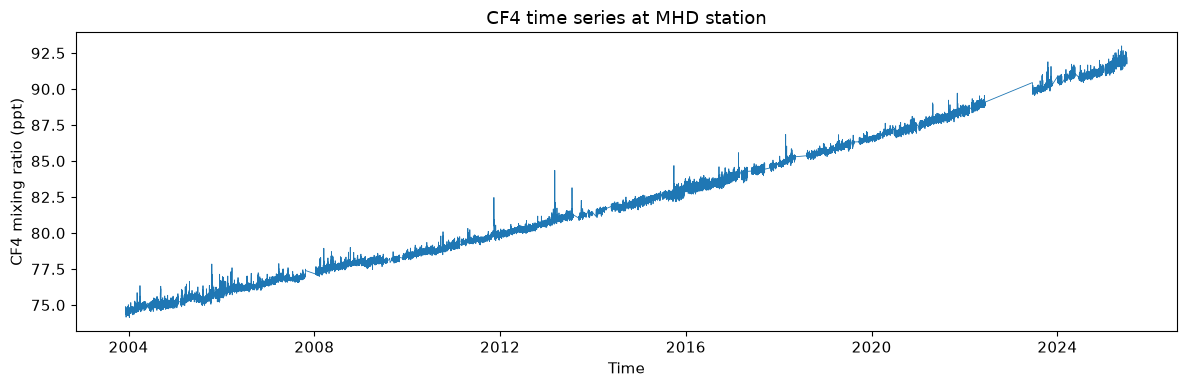

==== 4.3 ====
1. Mean value: 81.757
2. Median value: 80.992
3. Maximum value: 92.991
4. Minimum value: 74.126
5. Standard deviation: 4.760
6. P-value: 0.0000
Interpretation: p <= 0.05, the CF4 data does NOT follow a normal distribution.


In [22]:
#4
#4.1
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

#读取文件并输出原文件数据行数
df = pd.read_csv("agage_mhd_cf4_20260716.csv")
print("==== 4.1 ====")
print("原始数据行数：", len(df))

#全部清洗操作，结果直接赋值给 df_clean
df_clean = df.dropna()                                                 # 删除任意列缺失的行
df_clean = df_clean[(df_clean["mf"] >= 0) & (df_clean["mf"] <= 100)]   # 浓度范围过滤，根据数据整体情况处理质量不佳的数据
df_clean = df_clean[df_clean["mf_repeatability"] >= 0]                 # 重复性非负处理

#输出清洗后的数据行数
print("清洗后行数：", len(df_clean))

#把 CSV 读取出来文本字符串格式的时间，转换成 pandas 可以识别的 datetime 时间日期类型
df_clean["time_utc"] = pd.to_datetime(df_clean["time_utc"])

#输出清洗后数据的前5行
print(df_clean.head())


#4.2
print("==== 4.2 ====")

# 直接使用已经清洗好的 df_clean，新建画布，宽 12 高 4英寸
plt.figure(figsize=(12, 4))
#绘制折线图，X轴是时间，Y轴是浓度，线宽0.6
plt.plot(df_clean["time_utc"], df_clean["mf"], linewidth=0.6)

#X轴标签为 Time
plt.xlabel("Time")
#Y轴标签为 CF4 mixing ratio (ppt)
plt.ylabel("CF4 mixing ratio (ppt)")
#图表标签为CF4 time series at MHD station
plt.title("CF4 time series at MHD station")
#自动调整间距
plt.tight_layout()
#绘制图表
plt.show()


#4.3
#从 df_clean 里单独取出 CF₄浓度这一列，赋值给 mf_data 
mf_data = df_clean["mf"]

#计算浓度平均值，存入变量 mean_val
mean_val = mf_data.mean()
#计算浓度中位数，存入变量 median_val
median_val = mf_data.median()
#计算浓度最大值，存入变量 max_val
max_val = mf_data.max()
#计算浓度最小值，存入变量 min_val
min_val = mf_data.min()
#计算浓度标准差，反映数据离散波动程度，存入 std_val
std_val = mf_data.std()
#D'Agostino‑Pearson 正态性检验，用来检验一组数据是否服从正态分布；norm_stat 是检验统计量，norm_p 是p值
norm_stat, norm_p = stats.normaltest(mf_data)

#输出对变量进行简单统计检验的结果
print("==== 4.3 ====")
print(f"1. Mean value: {mean_val:.3f}")
print(f"2. Median value: {median_val:.3f}")
print(f"3. Maximum value: {max_val:.3f}")
print(f"4. Minimum value: {min_val:.3f}")
print(f"5. Standard deviation: {std_val:.3f}")
#输出p值并判断这一列数据是否服从正态分布
print(f"6. P-value: {norm_p:.4f}")
if norm_p > 0.05:
    print("Interpretation: p > 0.05, the CF4 data is approximately normally distributed.")
else:
    print("Interpretation: p <= 0.05, the CF4 data does NOT follow a normal distribution.")
